# AI Object Detection & Recognition System

An image-based object detection project built with **Python, YOLO11, OpenCV, pandas, and Gradio**.

The notebook loads a pretrained YOLO11n model, detects objects in an uploaded image, visualizes bounding boxes, summarizes detections, and exports a CSV report.


## 1. Install dependencies

In [1]:
!pip install ultralytics opencv-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 11.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


## 2. Load the pretrained YOLO11 model

In [8]:
from ultralytics import YOLO

# Önceden eğitilmiş YOLO modelini yükle
model = YOLO("yolo11n.pt")

print("AI Object Detection modeli hazır!")

AI Object Detection modeli hazır!


## 3. Upload an image

In [9]:
from google.colab import files

uploaded = files.upload()

KeyboardInterrupt: 

## 4. Detect and visualize objects


image 1/1 /content/WhatsApp Image 2026-11-03 at 16.28.24.jpeg: 448x640 1 cup, 1 potted plant, 1 dining table, 1 laptop, 1 book, 1 vase, 274.4ms
Speed: 11.0ms preprocess, 274.4ms inference, 17.4ms postprocess per image at shape (1, 3, 448, 640)


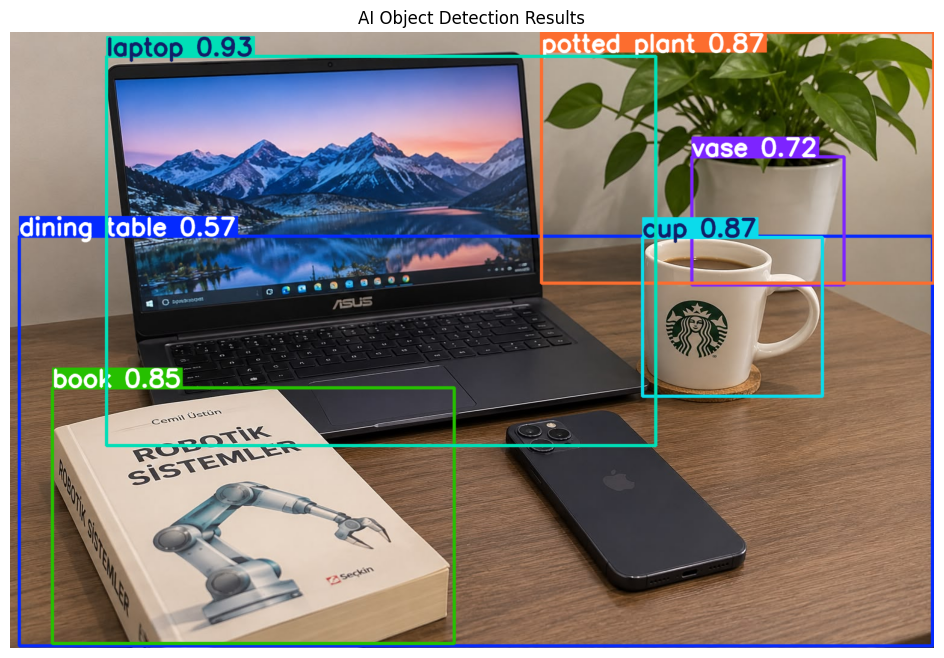

In [5]:
import cv2
import matplotlib.pyplot as plt

# Yüklenen fotoğrafın dosya adını al
image_path = list(uploaded.keys())[0]

# YOLO ile nesneleri algıla
results = model(image_path)

# Algılama sonuçlarını görselleştir
result_image = results[0].plot()

# OpenCV BGR görüntüsünü RGB'ye çevir
result_image = cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(result_image)
plt.axis("off")
plt.title("AI Object Detection Results")
plt.show()

## 5. Summarize detected objects

In [7]:
# Algılanan nesneleri listele ve say

detections = results[0].boxes
object_counts = {}

for box in detections:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    confidence = float(box.conf[0])

    object_counts[name] = object_counts.get(name, 0) + 1

print("OBJECT DETECTION REPORT")
print("-" * 30)

for name, count in object_counts.items():
    print(f"{name}: {count} adet")

print("-" * 30)
print(f"Toplam algılanan nesne: {len(detections)}")

OBJECT DETECTION REPORT
------------------------------
laptop: 1 adet
cup: 1 adet
potted plant: 1 adet
book: 1 adet
vase: 1 adet
dining table: 1 adet
------------------------------
Toplam algılanan nesne: 6


In [10]:
import pandas as pd

detection_data = []

for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]
    confidence = float(box.conf[0])

    detection_data.append({
        "Object": name,
        "Confidence (%)": round(confidence * 100, 2)
    })

df = pd.DataFrame(detection_data)

display(df)

,Object,Confidence (%)
0,laptop,93.46
1,cup,86.93
2,potted plant,86.65
3,book,85.12
4,vase,72.17
5,dining table,56.94


## 6. Export the detection report

In [11]:
# Export detection results as a CSV report
from google.colab import files

df.to_csv("object_detection_report.csv", index=False)
files.download("object_detection_report.csv")

print("Detection report successfully exported!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Detection report successfully exported!


In [12]:
!pip install gradio

## 7. Launch the Gradio web interface

In [13]:
import gradio as gr
import pandas as pd
import cv2
import tempfile

def detect_objects(image):
    if image is None:
        raise gr.Error("Please upload an image first.")

    result = model.predict(source=image)[0]
    annotated = result.plot()
    annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

    data = []
    for box in result.boxes:
        class_id = int(box.cls[0])
        name = model.names[class_id]
        confidence = float(box.conf[0])

        data.append({
            "Object": name,
            "Confidence (%)": round(confidence * 100, 2)
        })

    df_result = pd.DataFrame(data, columns=["Object", "Confidence (%)"])

    if df_result.empty:
        df_result.loc[0] = ["No objects detected", 0.0]

    report = tempfile.NamedTemporaryFile(suffix=".csv", delete=False)
    report.close()
    df_result.to_csv(report.name, index=False)

    return annotated, df_result, report.name


app = gr.Interface(
    fn=detect_objects,
    inputs=gr.Image(type="pil", label="Upload an Image"),
    outputs=[
        gr.Image(label="Detection Results"),
        gr.Dataframe(label="Detected Objects"),
        gr.File(label="Download CSV Report")
    ],
    title="AI Object Detection & Recognition System",
    description="Upload an image to detect and recognize objects using YOLO11."
)

app.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://58da9148f1c359abca.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
